# Proyecto final: ¿qué explica las emisiones de CO₂ per cápita de los países?

**Actividad 4 · Proyecto final del curso**

**Integrantes:** Juan Sebastian Gómez Jerez · Julian Esteban Bravo Daza · Ana Maria Villamil Camelo

**Fuente de datos:** Ritchie, H., & Roser, M. (2020). *CO₂ emissions*. Our World in Data. https://ourworldindata.org/co2-emissions
(dataset: https://github.com/owid/co2-data)

**Sección del artículo elegida:** *emisiones de CO₂ per cápita* (https://ourworldindata.org/per-capita-co2).

---
## Pregunta de investigación

El artículo de Our World in Data plantea que existe una relación fuerte entre el nivel de ingresos de un país y sus emisiones per cápita, pero que **aun con ingresos parecidos hay grandes diferencias**, y que la fuente de energía (fósil frente a nuclear y renovable) cumple un papel clave.

Con esa idea, este proyecto responde:

> **¿Cuánto del nivel de emisiones de CO₂ per cápita de un país se explica por su consumo de energía per cápita y por su ingreso (PIB per cápita)?**

## Estructura del proyecto y responsables

El proyecto se divide en tres notebooks que se ejecutan **en orden**, porque cada uno usa los datos que deja el anterior:

| Notebook | Contenido | Responsable |
|---|---|---|
| `01_limpieza_datos.ipynb` | Carga, exploración y limpieza de datos (este notebook) | Sebastian |
| `02_visualizacion.ipynb` | Visualización exploratoria | Julian |
| `03_modelo_regresion.ipynb` | Regresión lineal, interpretación y conclusiones | Ana y todo el grupo |


---
# Parte 1. Carga, exploración y limpieza de datos
*Responsable: Sebastian*

## 1.1 Librerías y parámetros

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Opciones de pandas y estilo de gráficos (una sola paleta para todo el notebook)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

AZUL = "#2a6fbb"      # color principal de datos
GRIS = "#8a8f98"      # contexto / comparaciones
ROJO = "#c8452f"      # resaltar un caso o la recta del modelo
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10,
})

# Año de análisis: 2019 es el último año previo a la pandemia con datos completos
# de PIB y energía (el PIB del dataset llega hasta 2022).
ANIO = 2019
RUTA_LOCAL = "../data/owid-co2-data.csv"
URL = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"

## 1.2 Carga del dataset

In [2]:
# Se usa la copia local del repositorio; si no existe, se descarga de Our World in Data.
if os.path.exists(RUTA_LOCAL):
    df = pd.read_csv(RUTA_LOCAL)
    print("Datos cargados desde el repositorio:", RUTA_LOCAL)
else:
    df = pd.read_csv(URL)
    print("Datos descargados desde Our World in Data")

print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
print(f"Años: {df['year'].min()} a {df['year'].max()} | Entidades distintas: {df['country'].nunique()}")
df.head()

Datos cargados desde el repositorio: ../data/owid-co2-data.csv
Filas: 56,269 | Columnas: 79
Años: 1750 a 2025 | Entidades distintas: 259


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,co2_including_luc,co2_including_luc_growth_abs,co2_including_luc_growth_prct,co2_including_luc_per_capita,co2_including_luc_per_gdp,...,share_global_cumulative_other_co2,share_global_flaring_co2,share_global_gas_co2,share_global_luc_co2,share_global_oil_co2,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,"2,802,560.000",NaN,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1.3 Exploración inicial

Se revisan las variables que usaremos: `co2_per_capita` (t de CO₂ por persona), `energy_per_capita` (kWh de energía primaria por persona), `gdp` (PIB, USD constantes) y `population`.

In [3]:
variables = ["country", "year", "iso_code", "population", "gdp", "co2", "co2_per_capita", "energy_per_capita"]
df[variables].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country,56269,259,Afghanistan,276,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,"56,269.000",NaN,NaN,NaN,"1,910.889",72.084,"1,750.000","1,862.000","1,916.000","1,971.000","2,025.000"
iso_code,48306,223,AFG,276,NaN,NaN,NaN,NaN,NaN,NaN,NaN
population,"44,124.000",NaN,NaN,NaN,"57,857,275.298","324,515,976.493",21.000,"339,208.250","2,285,948.500","9,708,646.500","8,231,613,067.000"
gdp,"15,367.000",NaN,NaN,NaN,"327,722,823,894.956","3,074,831,838,935.052","49,980,000.000","7,714,757,890.000","27,014,316,000.000","120,424,839,548.500","130,112,562,171,125.000"
co2,"30,219.000",NaN,NaN,NaN,416.444,"1,980.808",0.000,0.341,4.668,51.620,"38,995.105"
co2_per_capita,"27,238.000",NaN,NaN,NaN,3.935,18.758,0.000,0.169,1.030,4.315,"1,062.532"
energy_per_capita,"10,766.000",NaN,NaN,NaN,"24,003.208","31,996.084",0.000,"2,700.927","11,817.507","34,640.637","318,559.688"


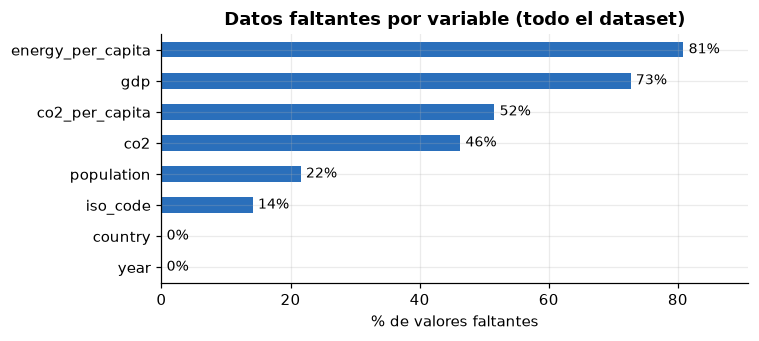

In [4]:
# Porcentaje de datos faltantes por variable en todo el dataset
faltantes = df[variables].isna().mean().mul(100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.2))
faltantes.plot.barh(ax=ax, color=AZUL)
ax.set_xlabel("% de valores faltantes")
ax.set_title("Datos faltantes por variable (todo el dataset)")
ax.invert_yaxis()
for i, v in enumerate(faltantes):
    ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=9)
ax.set_xlim(0, faltantes.max() + 10)
plt.tight_layout(); plt.show()

**Hallazgo:** el PIB y la energía per cápita tienen muchos faltantes. Además, el dataset mezcla **países con agregados** (por ejemplo *World*, *Europe*, *High-income countries*); esos agregados no tienen código ISO. Si los dejáramos, contaríamos dos veces las mismas emisiones. A continuación los separamos.

In [6]:
# Las entidades que NO son países no tienen código ISO de 3 letras
agregados = df.loc[df["iso_code"].isna(), "country"].unique()
print(f"Entidades sin código ISO (agregados): {len(agregados)}")
print(sorted(agregados)[:15], "...")

# Comprobación: el total mundial ("World") también es un agregado y quedará fuera
print("¿'World' está entre los agregados?", "World" in agregados)

Entidades sin código ISO (agregados): 36
['Africa', 'Africa (GCP)', 'Asia', 'Asia (GCP)', 'Asia (excl. China and India)', 'Central America (GCP)', 'Europe', 'Europe (GCP)', 'Europe (excl. EU-27)', 'Europe (excl. EU-28)', 'European Union (27)', 'European Union (28)', 'High-income countries', 'International aviation', 'International shipping'] ...
¿'World' está entre los agregados? True


## 1.4 Limpieza

In [7]:
# 1) Quedarnos solo con países (las filas con código ISO)
paises = df[df["iso_code"].notna()].copy()
print("Filas después de quitar agregados:", len(paises))

# 2) Verificar duplicados país-año
print("Duplicados país-año:", paises.duplicated(subset=["country", "year"]).sum())

# 3) Crear el PIB per cápita (USD constantes por persona)
paises["gdp_per_capita"] = paises["gdp"] / paises["population"]

# 4) Año de análisis y eliminación de filas sin las variables del modelo
cols_modelo = ["co2_per_capita", "energy_per_capita", "gdp_per_capita"]
datos = paises[paises["year"] == ANIO].copy()
print(f"\nPaíses en {ANIO} antes de limpiar: {len(datos)}")
print("Faltantes por variable del modelo:\n", datos[cols_modelo].isna().sum().to_string())

datos = datos.dropna(subset=cols_modelo)
print(f"Países en {ANIO} con datos completos: {len(datos)}")

Filas después de quitar agregados: 48306
Duplicados país-año: 0

Países en 2019 antes de limpiar: 223
Faltantes por variable del modelo:
 co2_per_capita        5
energy_per_capita    15
gdp_per_capita       59
Países en 2019 con datos completos: 164


In [9]:
# 5) Revisar valores atípicos y valores imposibles (negativos o cero)
print("Valores <= 0 por variable:\n", (datos[cols_modelo] <= 0).sum().to_string())
datos[cols_modelo].describe()

Valores <= 0 por variable:
 co2_per_capita       0
energy_per_capita    0
gdp_per_capita       0


,co2_per_capita,energy_per_capita,gdp_per_capita
count,164.000,164.000,164.000
mean,4.656,"26,361.811","18,814.747"
std,5.565,"35,373.439","19,660.798"
min,0.044,253.658,699.563
25%,0.805,"3,585.043","4,306.040"
50%,2.862,"14,520.421","12,428.368"
75%,6.214,"32,981.817","27,048.953"
max,33.787,"209,158.016","133,605.134"


In [10]:
# Países con las emisiones per cápita más altas: no son errores, son economías petroleras pequeñas
# (así lo señala también el artículo de OWID). Se conservan, pero se tendrán presentes en el análisis.
datos.nlargest(8, "co2_per_capita")[["country", "co2_per_capita", "energy_per_capita", "gdp_per_capita", "population"]]

,country,co2_per_capita,energy_per_capita,gdp_per_capita,population
42138,Qatar,33.787,"209,158.016","133,605.134","2,797,927.000"
50883,Trinidad and Tobago,27.445,"131,459.000","26,978.906","1,484,898.000"
4729,Bahrain,25.885,"155,659.125","38,779.330","1,485,675.000"
52895,United Arab Emirates,22.531,"129,769.297","78,374.266","9,377,855.000"
44956,Saudi Arabia,22.454,"97,377.938","55,366.739","30,472,809.000"
27224,Kuwait,19.632,"99,692.883","49,346.631","4,442,201.000"
3889,Australia,16.279,"65,938.531","49,268.910","25,482,714.000"
30030,Luxembourg,15.724,"76,250.828","55,021.134","620,167.000"


**Decisión sobre los atípicos:** los países con emisiones muy altas (Catar, Trinidad y Tobago, Baréin, Emiratos Árabes, etc.) son datos reales, no errores de medición. Se **conservan** y se justifica con el artículo: los mayores emisores per cápita son los productores de petróleo, sobre todo los de poca población. Más adelante veremos cómo afectan al modelo.

In [11]:
# Guardar el dataset limpio para que todo el grupo trabaje con los mismos datos
limpio = datos[["country", "iso_code", "year", "population", "gdp_per_capita",
                "energy_per_capita", "co2_per_capita", "co2"]].reset_index(drop=True)
os.makedirs("../data", exist_ok=True)
limpio.to_csv(f"../data/co2_limpio_{ANIO}.csv", index=False)
print(f"Guardado: ../data/co2_limpio_{ANIO}.csv  ->  {limpio.shape[0]} países, {limpio.shape[1]} columnas")
limpio.head()

Guardado: ../data/co2_limpio_2019.csv  ->  164 países, 8 columnas


,country,iso_code,year,population,gdp_per_capita,energy_per_capita,co2_per_capita,co2
0,Afghanistan,AFG,2019,"37,856,125.000","1,930.618","1,244.489",0.262,9.935
1,Albania,ALB,2019,"2,885,011.000","11,538.863","8,630.006",1.682,4.853
2,Algeria,DZA,2019,"43,294,551.000","13,625.389","16,037.789",4.315,186.818
3,Angola,AGO,2019,"32,375,633.000","4,985.506","3,018.674",0.694,22.465
4,Argentina,ARG,2019,"44,973,469.000","18,167.465","20,582.312",3.978,178.894
